# Experiment 13: Car Price Prediction
**Course:** ITA06 - Machine Learning (Lab)

## Aim
Implement a **Car Price Prediction** model using Python.

## Note on the data
A **synthetic used-car data set** (brand, year, kilometres driven, fuel, transmission, engine size, power) is generated with a fixed seed so that the notebook is self-contained. To use a real CSV (e.g. Kaggle *Car details* data) replace the first data cell with `df = pd.read_csv('your_file.csv')` and adjust the column lists.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(42)
n = 2500
brand = rng.choice(['Maruti', 'Hyundai', 'Honda', 'Toyota', 'BMW', 'Audi'], n, p=[.28, .25, .17, .15, .08, .07])
base = {'Maruti': 4.5, 'Hyundai': 5.5, 'Honda': 7, 'Toyota': 9, 'BMW': 24, 'Audi': 22}
year = rng.integers(2008, 2025, n)
km = (rng.gamma(4, 14000, n) * (2025 - year + 1) / 8).clip(2000, 300000).round(-2)
fuel = rng.choice(['Petrol', 'Diesel', 'CNG'], n, p=[.55, .40, .05])
trans = rng.choice(['Manual', 'Automatic'], n, p=[.7, .3])
engine = rng.choice([800, 1000, 1200, 1500, 2000, 2500, 3000], n)
power = (engine / 14 + rng.normal(0, 6, n)).clip(35, 300).round(1)

price = (np.array([base[b] for b in brand]) * (0.9 ** (2025 - year)) * (1 + engine / 4000)
         * (1 - km / 900000) * np.where(trans == 'Automatic', 1.12, 1) * np.where(fuel == 'Diesel', 1.08, 1)
         + rng.normal(0, 0.4, n)).clip(0.3)
df = pd.DataFrame({'Brand': brand, 'Year': year, 'Km_Driven': km, 'Fuel': fuel, 'Transmission': trans,
                   'Engine_cc': engine, 'Power_bhp': power, 'Price_Lakhs': price.round(2)})
df.to_csv('car_price_synthetic.csv', index=False)
print(df.shape)
df.head()

(2500, 8)


,Brand,Year,Km_Driven,Fuel,Transmission,Engine_cc,Power_bhp,Price_Lakhs
0,Toyota,2011,113000.0,Diesel,Manual,1500,109.4,2.12
1,Hyundai,2008,43900.0,Diesel,Manual,2500,193.0,0.72
2,BMW,2018,27100.0,Diesel,Automatic,1200,95.6,17.86
3,Honda,2019,48200.0,Diesel,Manual,800,67.2,5.10
4,Maruti,2021,41700.0,Diesel,Manual,1200,80.9,3.63


          Year  Km_Driven  Engine_cc  Power_bhp  Price_Lakhs
count  2500.00    2500.00    2500.00    2500.00      2500.00
mean   2015.87   70631.16    1763.32     126.11         5.44
std       4.85   50962.78     761.86      54.70         5.53
min    2008.00    2000.00     800.00      38.30         0.30
25%    2012.00   32675.00    1000.00      77.78         2.15
50%    2016.00   58550.00    1500.00     109.85         3.80
75%    2020.00   95725.00    2500.00     176.92         6.44
max    2024.00  300000.00    3000.00     230.80        41.49


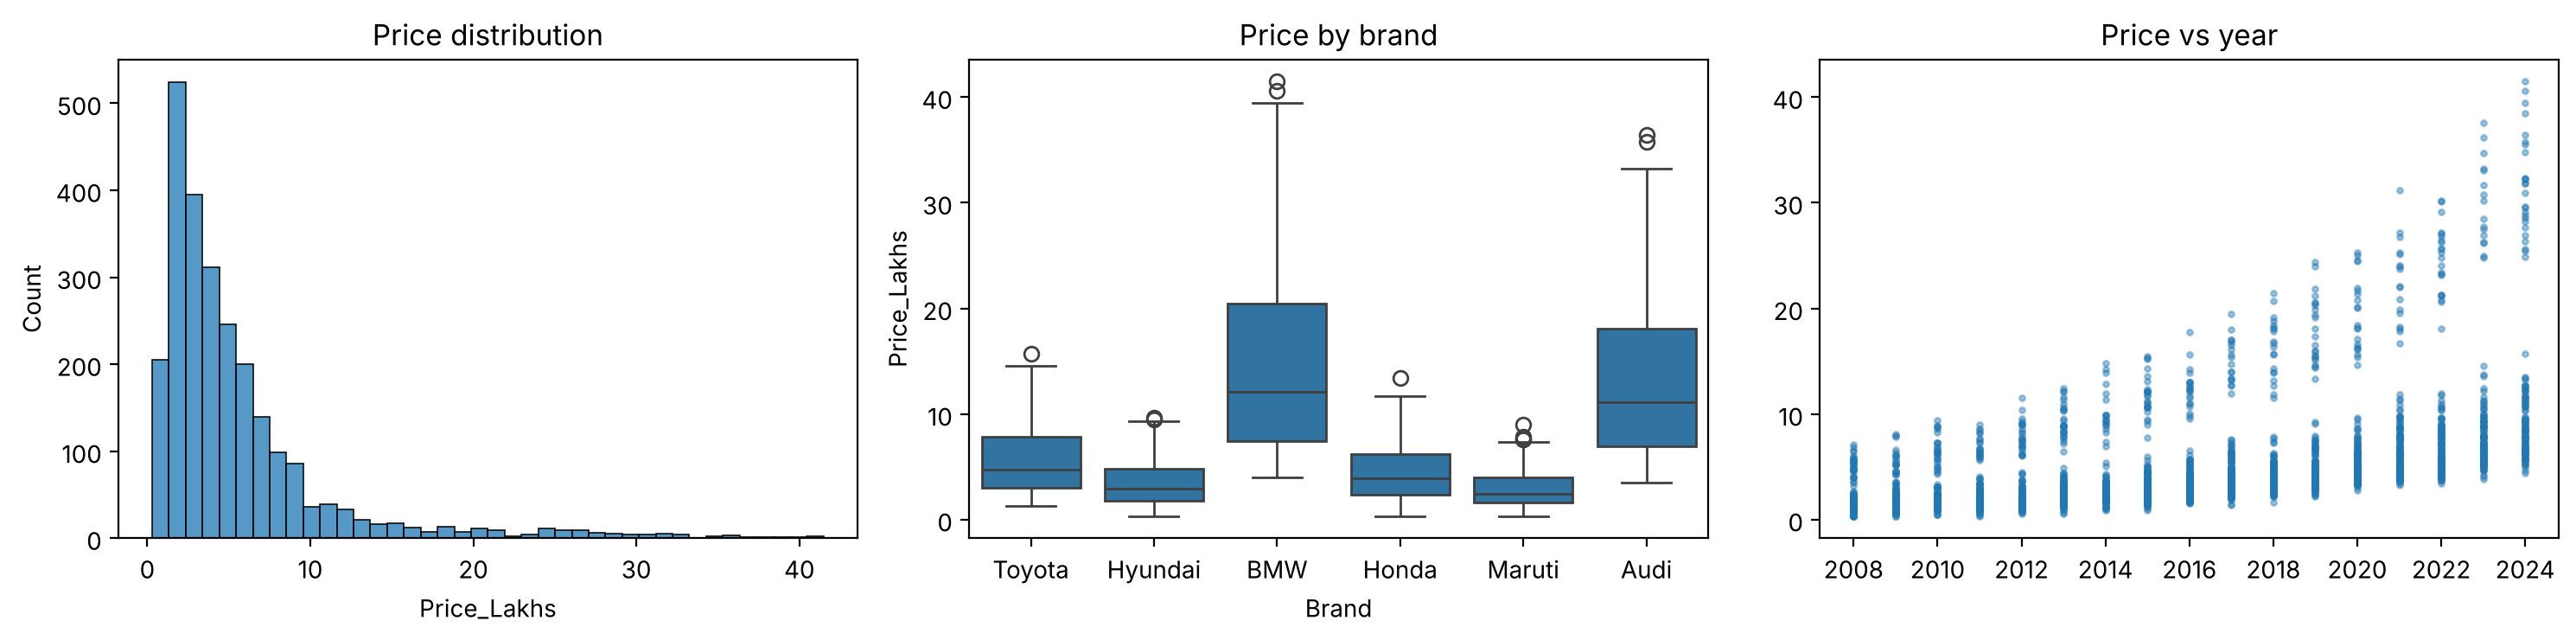

In [2]:
print(df.describe().round(2))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
sns.histplot(df['Price_Lakhs'], bins=40, ax=ax[0]); ax[0].set_title('Price distribution')
sns.boxplot(data=df, x='Brand', y='Price_Lakhs', ax=ax[1]); ax[1].set_title('Price by brand')
ax[2].scatter(df['Year'], df['Price_Lakhs'], s=5, alpha=0.4); ax[2].set_title('Price vs year')
plt.tight_layout(); plt.show()

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

X = df.drop(columns='Price_Lakhs'); y = df['Price_Lakhs']
cat = ['Brand', 'Fuel', 'Transmission']; num = ['Year', 'Km_Driven', 'Engine_cc', 'Power_bhp']
prep = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), cat),
                          ('num', StandardScaler(), num)])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

models = {'Linear Regression': LinearRegression(),
          'Random Forest': RandomForestRegressor(n_estimators=200, random_state=42),
          'Gradient Boosting': GradientBoostingRegressor(random_state=42)}
rows, fitted = [], {}
for name, m in models.items():
    pipe = Pipeline([('prep', prep), ('model', m)]).fit(X_train, y_train)
    p = pipe.predict(X_test); fitted[name] = pipe
    rows.append({'Model': name, 'R2': r2_score(y_test, p), 'MAE (Lakhs)': mean_absolute_error(y_test, p),
                 'RMSE (Lakhs)': np.sqrt(mean_squared_error(y_test, p))})
results = pd.DataFrame(rows).round(4)
results

,Model,R2,MAE (Lakhs),RMSE (Lakhs)
0,Linear Regression,0.7864,1.5798,2.4883
1,Random Forest,0.9810,0.4964,0.7430
2,Gradient Boosting,0.9826,0.4737,0.7095


Best model: Gradient Boosting


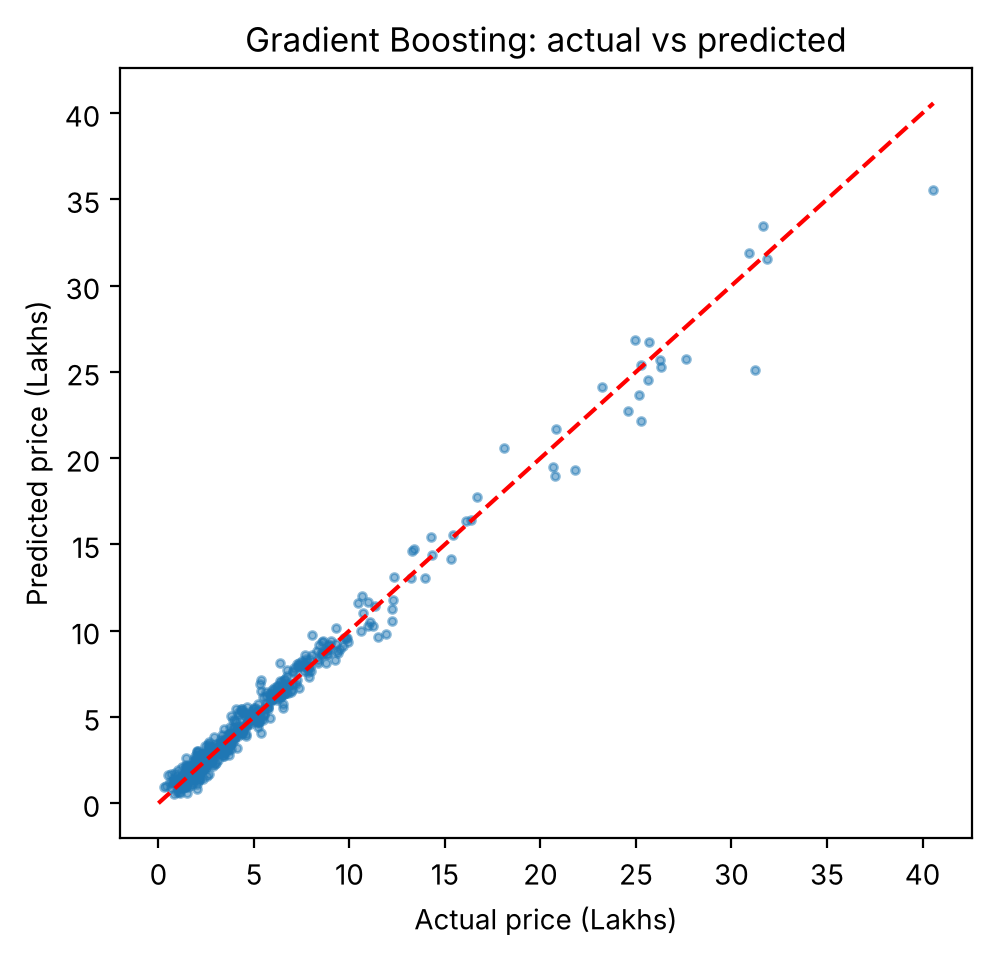

Predicted price of the new car: 5.26 Lakhs


In [4]:
best_name = results.sort_values('R2', ascending=False).iloc[0]['Model']
best = fitted[best_name]
pred = best.predict(X_test)
print('Best model:', best_name)

plt.figure(figsize=(5.5, 5))
plt.scatter(y_test, pred, s=8, alpha=0.5)
lim = [0, max(y_test.max(), pred.max())]
plt.plot(lim, lim, 'r--'); plt.xlabel('Actual price (Lakhs)'); plt.ylabel('Predicted price (Lakhs)')
plt.title(f'{best_name}: actual vs predicted'); plt.show()

new_car = pd.DataFrame([{'Brand': 'Honda', 'Year': 2019, 'Km_Driven': 45000, 'Fuel': 'Petrol',
                         'Transmission': 'Manual', 'Engine_cc': 1500, 'Power_bhp': 110.0}])
print(f'Predicted price of the new car: {best.predict(new_car)[0]:.2f} Lakhs')

## Result
Tree-ensemble models capture the non-linear drop in price with age and mileage better than plain linear regression, giving the highest R2 and lowest error. The best pipeline was used to estimate the price of a new car.